### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Diesel Price Dataset

In [8]:
temp_diesel = get_dataset('\\Datasets\\diesel_price.csv')
temp_diesel.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.345,NaN,1.185,NaN,0.82,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.210,NaN,1.190,NaN,0.70,NaN,NaN,NaN,NaN
3,Africa Western and Central,AFW,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.220,NaN,1.155,NaN,0.88,NaN,NaN,NaN,NaN
4,Angola,AGO,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.420,NaN,0.510,NaN,0.82,NaN,NaN,NaN,NaN


In [9]:
temp_diesel = temp_diesel[temp_diesel['Country Code'] == 'MMR']
temp_diesel

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,Pump price for diesel fuel (US$ per liter),EP.PMP.DESL.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.93,NaN,0.51,NaN,NaN,NaN,NaN


In [10]:
date = temp_diesel.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
diesel_price = temp_diesel.copy()
diesel_price = diesel_price[date]
diesel_price = diesel_price.values
diesel_price

array([[ nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,
         nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,
         nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,  nan,
         nan,  nan,  nan,  nan,  nan, 0.12,  nan, 0.12,  nan, 0.28,  nan,
        0.1 ,  nan, 0.75,  nan, 0.52,  nan, 0.8 ,  nan,  nan,  nan, 0.93,
         nan, 0.51,  nan,  nan,  nan,  nan]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
diesel_price = diesel_price[0][38:]
date = date[38:]
diesel_price.shape

(23,)

In [15]:
diesel = pd.DataFrame()
diesel['diesel_price'] = diesel_price
diesel

,diesel_price
0,0.12
1,NaN
2,0.12
3,NaN
4,0.28
5,NaN
6,0.10
7,NaN
8,0.75
9,NaN


##### Filling data with linear interpolation

In [16]:
diesel = diesel.interpolate(method='linear')
diesel

,diesel_price
0,0.1200
1,0.1200
2,0.1200
3,0.2000
4,0.2800
5,0.1900
6,0.1000
7,0.4250
8,0.7500
9,0.6350


In [17]:
diesel['date']=date
diesel = diesel.set_index('date')
diesel.columns=['diesel_price']
diesel.head()

,diesel_price
date,
1998-01-01,0.12
1999-01-01,0.12
2000-01-01,0.12
2001-01-01,0.20
2002-01-01,0.28


### Merge diesel_price and food_price

In [18]:
food_diesel = food_price.join(diesel, how='inner')
food_diesel

,food_price,diesel_price
date,,
2008-01-01,0.563348,0.5200
2009-01-01,0.452433,0.6600
2010-01-01,0.505708,0.8000
2011-01-01,0.546463,0.8325
2012-01-01,0.467904,0.8650
2013-01-01,0.513739,0.8975
2014-01-01,0.918071,0.9300
2015-01-01,1.059368,0.7200
2016-01-01,1.182692,0.5100


### Compute price change using pct_change()

Even if the two series are totally unrelated, you could still get a very high correlation. 
We should use priceage of data instead of original data.

In [19]:
returns= food_diesel.pct_change()
returns

,food_price,diesel_price
date,,
2008-01-01,NaN,NaN
2009-01-01,-0.196887,0.269231
2010-01-01,0.117753,0.212121
2011-01-01,0.080591,0.040625
2012-01-01,-0.143759,0.039039
2013-01-01,0.097959,0.037572
2014-01-01,0.787035,0.036212
2015-01-01,0.153907,-0.225806
2016-01-01,0.116412,-0.291667


In [20]:
correlation=returns['food_price'].corr(returns['diesel_price'])
correlation

-0.1487892372447118

### Make scatter plot

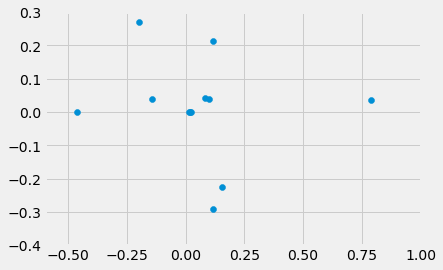

In [21]:
plt.scatter(returns['food_price'],returns['diesel_price'])
plt.show()

### Normalization

In [22]:
date = food_diesel.index

In [23]:
scaler = MinMaxScaler()

In [24]:
food_diesel = scaler.fit_transform(food_diesel)
food_diesel = pd.DataFrame(food_diesel)
food_diesel['date'] = date
food_diesel.set_index('date', inplace=True)
food_diesel.columns = ['food_price', 'diesel_price']
food_diesel.head()

,food_price,diesel_price
date,,
2008-01-01,0.138512,0.023810
2009-01-01,0.000000,0.357143
2010-01-01,0.066530,0.690476
2011-01-01,0.117426,0.767857
2012-01-01,0.019321,0.845238


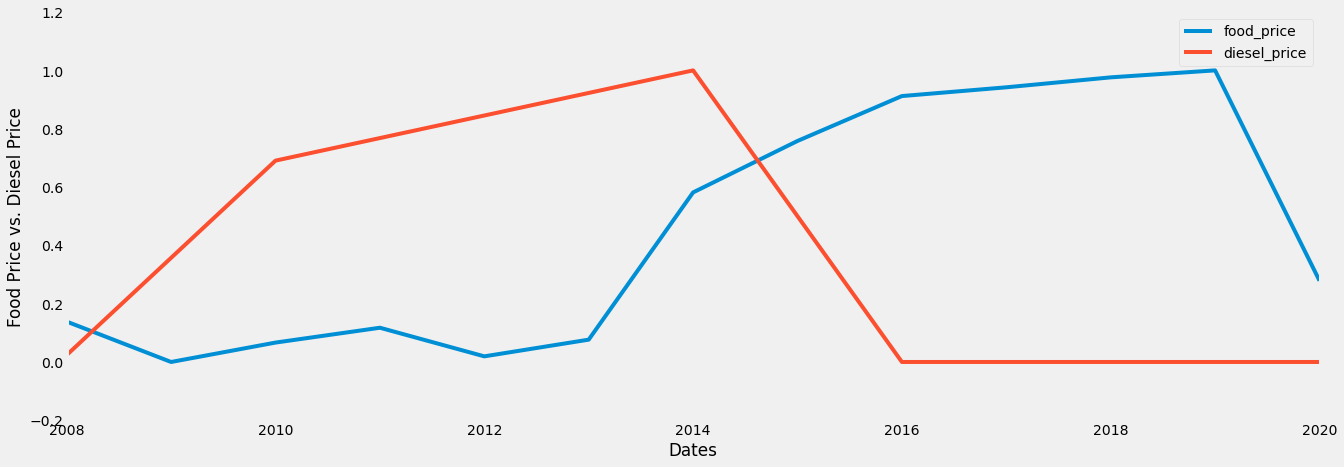

In [25]:
line_ax = food_diesel.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Diesel Price')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is no relation between Food Price and Diesel Price</span>